![Nagłówek - Fundusze Europejskie dla Rozwoju Społecznego, Rzeczpospolita Polska, Dofinansowane Przez Unię Europejską i Politechnika Wrocławska](./img/header.png)

# Laboratorium kursu Wstęp do Sztucznej Inteligencji
## Systemy logiczne i wnioskowanie

Do pełnego wykonania laboratorium konieczne jest pobranie zbioru danych Student Performance [1], dostępnego np. [pod linkiem](https://archive.ics.uci.edu/dataset/320/student+performance). Należy rozpakować archiwum i plik `student-mat.csv` umieścić w tym samym folderze co niniejszy notatnik.

In [20]:
import pandas as pd
import seaborn as sns
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
from helpers import *   # Raczej tak nie robimy, ale w tym laboratorium musimy zaimportować wszystko

## Reguły asocjacyjne

Pisanie reguł przez ekspertów ma dwa zasadnicze ograniczenia: jest pracochłonne i łatwo o pomyłkę. Dlatego w SI rozwinięto metody **indukcji reguł z danych**. Otrzymywane reguły nie są jednak regułami logicznymi - opisują, jak często coś występowało w zebranych danych, ale nie gwarantują, że nastąpi to *zawsze*. Dlatego opisujemy je liczbami (wsparciem i ufnością).

W tej części zajmiemy się przedstawianiem i odkrywaniem wiedzy w postaci *reguł asocjacyjnych*, czyli konstrukcji:

* *JEŻELI [warunek] TO [konkluzja]*

(poprzednik bywa nazywany warunkiem lub przesłanką, następnik konkluzją)

zapisywanych często symbolem znanym z logiki

* $[poprzednik] \implies [następnik]$

np.

* $pada\_śnieg \implies kierowca\_zaskoczony$
* $zakup\_kawy \implies zakup\_ciastka$
* $baza\ lakieru\ Firmy\ S \implies Top\ lakieru\ Firmy\ S$
* $temperatura < 0 \land pada \implies nawierzchnia\ pokryta\ lodem$

Uwaga: choć zapis jest taki sam, to **nie** jest to implikacja logiczna.

Ogólnie mówiąc, reguły asocjacyjne to reguły, które mówią nam o kojarzeniu lub współwystępowaniu obserwacji. Ich podstawowym celem jest opisywanie, które elementy (atrybuty, zdarzenia, produkty) mają tendencję do wspólnego występowania w ramach jednej obserwacji (tradycyjnie nazywanej transakcją).

**UWAGA** Reguły asocjacyjne **nie** mówią nic o przyczynowości relacji. 

### Zapis reguł

Jak wiesz z wcześniejszych zajęć, dane w komputerze przechowujemy w odpowiednich strukturach. Chociaż moglibyśmy każdą obserwację przechowywać w postaci zwykłego zbioru atrybutów, np. 

```python
o0 = {"szynka", "ser", "masło", "chleb"}
o1 = {"szynka", "ser"}
```
*(W Pythonie powyższy zapis tworzy **zbiór**. Tak jak w matematyce, kolejność elementów nie ma znaczenia, a każdy element występuje najwyżej raz.)*

z punktu widzenia obliczeń często praktyczniejsze jest przechowywanie informacji w tabelach. Zwyczajowo każda kolumna oznacza atrybut, a każdy wiersz obserwację, np.

| Indeks | szynka | ser | masło | chleb |
| :--- | :--- | :--- | :--- | :--- |
| 0. | True | True | True | True |
| 1. | True | True | False | False |
| 2. | False | True | True | True |
| 3. | True | True | True | True |
| 4. | False | True | False | False |
| 5. | True | True | False | True |
| 6. | False | False | False | True |
| 7. | True | True | True | True |

Oczywiście atrybuty mogą przyjmować różne wartości, w tym niebinarne, np.

| Indeks | szynka | ser | masło | chleb |
| :--- | :--- | :--- | :--- | :--- |
| 0. | Szwarcwaldzka | Cheddar | Osełka | Na zakwasie |
| 1. | Gotowana | Gouda | Brak | Brak |
| 2. | Brak | Mimolette | Kostka | Drożdżowy |


## Reguły mające źródło w intuicji

Reguły przedstawione powyżej moglibyśmy wymyślić intuicyjnie na podstawie własnej wiedzy o świecie i przeżytych doświadczeń (np. zima często zaskakuje kierowców). Choć intuicja nierzadko prowadzi do reguł dobrze opisujących świat, bywa też zawodna, zwłaszcza przy wymyślaniu skomplikowanych zależności. Z tego powodu reguły należy weryfikować z danymi. 

Rozważmy inny przykład - symulowane dane na temat przejazdów linii tramwajowych we Wrocławiu.

In [21]:
trams_df = load_trams()
trams_df.head()

,Linia,Pora_Dnia,Opóźniony,Wykolejenie,Awaria_Zasilania,Przez_Arkady_Capitol
0,4,Szczyt_Popołudniowy,Nie,Nie,Nie,Nie
1,10,Szczyt_Popołudniowy,Tak,Tak,Tak,Tak
2,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak
3,17,Szczyt_Popołudniowy,Tak,Nie,Nie,Nie
4,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak


Możemy skojarzyć, że opóźnienia komunikacji miejskiej często wiążą się ze wzmożonym ruchem w czasie godzin szczytu. Czy zatem możemy stworzyć regułę mówiącą, że w czasie szczytu należy spodziewać się opóźnień?

$$Pora\_Dnia = Szczyt \implies Opóźniony = Tak$$

## Testowanie reguł

Jak przetestować naszą regułę? Moglibyśmy np. sprawdzić, jak często jest spełniona w rzeczywistości. 

* Gdybyśmy siedzieli na przystanku przez cały dzień i zapisywali dla każdego kursu czy jest opóźniony (atrybut *Opóźniony*), oraz odpowiadającą porę dnia (atrybut *Pora_Dnia* o wartościach *Poza_Szczytem, Szczyt_Poranny, Szczyt_Popołudniowy*), moglibyśmy sprawdzić ile razy tramwaje przyjechały w szczycie `Pora_Dnia = Szczyt` i były opóźnione `Opóźniony = Tak`. Jeżeli porównamy tę liczbę ze wszystkimi zapisanymi przyjazdami, otrzymamy informację, jaki procent wszystkich przyjazdów to przyjazdy *opóźnione i w szczycie*. Ta informacja odpowiada na pytanie: *Ile spośród wszystkich kursów, to kursy opóźnione w godzinach szczytu?*

* Możemy też uznać, że bardziej niż stosunek do wszystkich kursów, interesuje nas odpowiedź na pytanie *Ile spośród kursów w szczycie było opóźnionych?* Odpowiedź na to pytanie też byłaby łatwa do uzyskania z naszych danych - możemy policzyć wszystkie zapisane kursy w godzinach szczytu `Pora_Dnia = Szczyt` i sprawdzić ile **spośród nich** było opóźnionych `Opóźniony = Tak`.

Te dwa sposoby oceny, to dwie podstawowe miary wykorzystywane do oceny reguł asocjacyjnych. Ich nazwy to (kolejno) *wsparcie* (*ang. support*) i *ufność* (*ang. confidence*).

* Wsparciem (*supp*) reguły nazywamy stosunek liczby obserwacji, w których występuje **jednocześnie** poprzednik i następnik, do liczby wszystkich obserwacji.

* Ufnością (*conf*) reguły nazywamy stosunek liczby obserwacji, w których występuje jednocześnie poprzednik i następnik, do liczby obserwacji, w których występuje poprzednik. 

### Wsparcie (Support)

Wsparcie możemy zdefiniować zarówno dla reguły, jak i dla zbioru atrybutów.

1. Wsparcie dla zbioru atrybutów $X$ to odsetek obserwacji w bazie danych $D$, które zawierają ten zbiór.

    $$supp(X) = \frac{|\{t \in D \mid X \subseteq t\}|}{|D|}$$

    Gdzie:
    * $|\{t \in D \mid X \subseteq t\}|$ to liczba obserwacji $t$, które zawierają $X$. Jeżeli $X = \{Linia=10\}$, to będzie to liczba zaobserwowanych kursów linii 10.
    * $|D|$ to łączna liczba wszystkich obserwacji (wszystkich kursów).

    Wsparcie jest **oszacowaniem** prawdopodobieństwa $P(X)$ na podstawie danych, w tym przypadku prawdopodobieństwa, że losowo zaobserwowany kurs będzie *kursem linii 10*.

2. Wsparcie dla reguły $X \implies Y$ jest definiowane jako wsparcie zbioru atrybutów będącego **sumą** poprzednika i następnika. Mierzy ono, jak często $X$ i $Y$ występują **razem** w całej bazie danych.

    $$supp(X \implies Y) = supp(X \cup Y)$$

    Czyli:

    $$supp(X \cup Y) = \frac{|\{t \in D \mid (X \cup Y) \subseteq t\}|}{|D|}$$

    Wsparcie jest oszacowaniem prawdopodobieństwa łącznego $P(X \cap Y)$. Jeżeli $X = \{Linia=10\}$ i $Y = \{Opóźniony = Tak\}$, to $X \cup Y = \{Linia=10, Opóźniony = Tak\}$. $P(X \cap Y)$ będzie prawdopodobieństwem, że losowo zaobserwowany kurs będzie *opóźnionym kursem linii 10*. 
    
    Zauważ, że $X \cup Y$ oznacza sumę zbiorów atrybutów (nowy, większy zbiór atrybutów). W tym przypadku, jeżeli $X = \{Pora\ dnia = Szczyt\}$, a $Y = \{Opóźniony = Tak\}$, to $X \cup Y = \{Pora\ dnia = Szczyt, Opóźniony = Tak\}$. 
    
    $P(X \cap Y)$ oznacza zaś przecięcie wystąpień $X$ i $Y$ w całym zbiorze danych, czyli zdarzenia dla których zarówno atrybuty z $X$ przyjmują wartość True, jak i atrybuty z $Y$ przyjmują wartość True.

Wsparcie określa ile obserwacji w zbiorze potwierdza regułę. Jeżeli wsparcie reguły przyjmie niską wartość, oznacza to, że ogólnie niewiele obserwacji (kursów, klientów) zachowuje się zgodnie z regułą. Reguły o bardzo niskim lub bardzo wysokim wsparciu są najczęściej mało interesujące, gdyż są mało reprezentatywne lub zbyt powszechne i już dobrze znane (oczywiste).

### Ufność (Confidence)

**Ufność** reguły $X \implies Y$ mierzy, jaki odsetek transakcji, które zawierają $X$, zawiera *również* $Y$.

Definiujemy ją jako stosunek wsparcia reguły do wsparcia samego poprzednika:

$$conf(X \implies Y) = \frac{supp(X \cup Y)}{supp(X)}$$

Jeśli rozwiniemy ten wzór, skracając $|D|$ z licznika i mianownika, otrzymamy postać:

$$conf(X \implies Y) = \frac{|\{t \in D \mid (X \cup Y) \subseteq t\}|}{|\{t \in D \mid X \subseteq t\}|}$$

Gdzie:
* Licznik to liczba transakcji zawierających *jednocześnie* $X$ i $Y$ (np. *opóźnione kursy linii 10*).
* Mianownik to liczba transakcji zawierających $X$ (np. *wszystkie kursy linii 10*).

Jest to prawdopodobieństwo warunkowe $P(Y \mid X)$ szacowane na podstawie danych. Ufność mówi nam, jaka jest szansa że *kurs będzie opóźniony, jeżeli wiemy, że jest to linia 10*. 

Ufność określa jak pewna jest reguła asocjacyjna, czyli jak bardzo ufamy, że *gdy $X$ to też $Y$*. Niska wartość ufności świadczy o małej wiarygodności reguły. Wysoka ufność oznacza, że **gdy** zachodzi X, prawie zawsze zachodzi też Y. Nie mówi jednak o częstości zachodzenia X (od tego jest wsparcie).

### Sprawdzenie reguły

Wiemy już, jak oceniać reguły. Sprawdźmy zatem, jakie wartości wsparcia i ufności otrzymamy dla wymyślonej przez nas reguły:

$$Pora\_Dnia = Szczyt \implies Opóźniony = Tak$$

In [22]:
antecedent = (trams_df["Pora_Dnia"] == "Szczyt_Popołudniowy") | (trams_df["Pora_Dnia"] == "Szczyt_Poranny") # Poprzednik. Ponieważ Szczyt_Popołudniowy i Szczyt_Poranny to dwie kategorie, łączymy je operatorem OR (|). Oznacza to, że interesują nas przypadki, gdy Pora_Dnia jest równa jednej z tych dwóch wartości.
consequent = trams_df["Opóźniony"] == "Tak" # Następnik

# Obliczamy wsparcie - support
supp_num = len(trams_df[antecedent & consequent])
supp_denom = len(trams_df)
support = supp_num / supp_denom

# Obliczamy ufność - confidence
conf_num = len(trams_df[antecedent & consequent])
conf_denom = len(trams_df[antecedent])
confidence = conf_num / conf_denom

print(f"Wsparcie: {support:.2f}, ufność: {confidence:.2f}")

Wsparcie: 0.55, ufność: 0.75


Co oznaczają powyższe wartości? Wsparcie mówi, jaki odsetek wszystkich zapisanych kursów to kursy w szczycie, które były opóźnione. Ufność mówi, jaki odsetek w szczycie stanowiły kursy opóźnione. Zastanów się, skąd się biorą wysokie wartości miar. 

## Odkrywanie asocjacji - algorytm Apriori

Moglibyśmy w sposób jak powyżej odkrywać reguły w danych, lecz taki proces byłby bardzo długi i wyczerpujący, oraz podatny na pominięcia pewnych reguł (na skutek niewłaściwej intuicji lub zwykłego zmęczenia). Algorytmy odkrywania asocjacji służą do znajdowania zależności w sposób automatyczny, co przyspiesza cały proces szukania i zmniejsza ryzyko przedwczesnej eliminacji wartościowych reguł (jeszcze przed sprawdzeniem ich z danymi). Jednym z najbardziej znanych algorytmów służących do odkrywania reguł asocjacyjnych jest **algorytm Apriori**.

Wykorzystamy zbiór danych o kursach tramwajów do przeprowadzenia "analizy koszykowej" (nazwanej od koszyków sklepowych i tradycyjnego zastosowania reguł asocjacyjnych). My zamiast koszyków mamy obserwacje kursów. W naszej analizie będziemy szukali reguł opisujących **współwystępowanie dowolnych cech**, tak jak w analizie zakupów szukamy dowolnych zakupionych razem produktów.

Zanim uruchomimy **algorytm Apriori**, musimy przekształcić dane do postaci binarnych atrybutów (zrobimy to poniżej).

**Jak działa Apriori?**
Algorytm ten znajduje *częste zbiory cech* (frequent itemsets). Jego spryt polega na wykorzystaniu obserwacji, że wszystkie podzbiory zbioru częstego muszą być zbiorami częstymi.
Ta obserwacja pozwala drastycznie ograniczyć liczbę kombinacji do sprawdzenia, ponieważ nie musimy sprawdzać każdej możliwej reguły w zbiorze. Zamiast tego najpierw dokonujemy redukcji możliwych zbiorów atrybutów do tych, które są częste. Równoważnie, jeśli zbiór jest rzadki, to każdy zbiór, który go zawiera, też jest rzadki.

Co jednak oznacza *częsty* w tym algorytmie? Jakie wsparcie jest uważane za wystarczające?

- **Minimalna częstość występowania, czyli minimalne wsparcie jest parametrem algorytmu określanym przez użytkownika.**

- Dodatkowo, chcemy być pewni uzyskanych reguł (confidence), więc **kolejnym parametrem jest minimalna ufność**. W ostatniej fazie algorytmu, wygenerowane reguły są sprawdzane pod kątem spełniania minimalnej ufności. Reguły, których ufność jest mniejsza od zadanej są odrzucane.

**Głównym celem** algorytmu Apriori jest znalezienie **wszystkich** zbiorów atrybutów, które występują *wystarczająco często* w naszej bazie danych.

Zanim przejdziemy do przykładu musimy przetworzyć trochę zbiór danych, ponieważ implementacja z której skorzystamy wymaga binarnych atrybutów (Tak / Nie).

* Opóźniony, Wykolejenie, Awaria_Zasilania, Przez_Arkady_Capitol są już atrybutami binarnymi - zmienimy wartości Tak / Nie na logiczne True / False
* Linia i Pora_Dnia są atrybutami kategorycznymi. Aby zmienić je na formę binarną, dla każdej kategorii utworzymy nowy binarny atrybut, mówiący o tym, czy dany wpis dotyczy danej kategorii. Jeżeli np. atrybut *Linia* miał wartość 10, to teraz stworzymy atrybut *Linia 10* przyjmujący wartości True lub False.
* Pory *Szczyt_Poranny* i *Szczyt_Popołudniowy* połączymy w jedną kategorię *Szczyt*, bo nasza reguła dotyczy po prostu szczytu.

In [23]:
trams_df.head()

,Linia,Pora_Dnia,Opóźniony,Wykolejenie,Awaria_Zasilania,Przez_Arkady_Capitol
0,4,Szczyt_Popołudniowy,Nie,Nie,Nie,Nie
1,10,Szczyt_Popołudniowy,Tak,Tak,Tak,Tak
2,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak
3,17,Szczyt_Popołudniowy,Tak,Nie,Nie,Nie
4,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak


In [24]:
len(trams_df[trams_df['Awaria_Zasilania'] == 'Tak'])

21

In [25]:
trams_df = preprocess_trams(trams_df)
trams_df.head()

,Linia 4,Linia 5,Linia 10,Linia 17,Poza_Szczytem,Szczyt,Opóźniony,Wykolejenie,Awaria_Zasilania,Przez_Arkady_Capitol
0,True,False,False,False,False,True,False,False,False,False
1,False,False,True,False,False,True,True,True,True,True
2,False,False,False,True,False,True,True,True,False,True
3,False,False,False,True,False,True,True,False,False,False
4,False,False,False,True,False,True,True,True,False,True


W tej nowej formie, nasza reguła dotycząca opóźnień przyjęłaby formę:

$$Szczyt = True \implies Opóźniony = True$$

Jesteśmy gotowi do uruchomienia algorytmu Apriori.


### Przykład

Użyjmy naszego przykładu MPK:
* Ustawiamy `min_support = 30%`.
* Ustawiamy `min_confidence = 80%`.
* To oznacza, że *rzeczywiste minimalne wsparcie* (count) wynosi $\lceil 0.3 \times 100 \rceil = 30$ transakcji. Itemset (zbiór atrybutów) jest "częsty", jeśli wystąpił co najmniej 30 razy.

In [30]:
min_support = 0.2
min_confidence = 0.9

trams_df

,Linia 4,Linia 5,Linia 10,Linia 17,Poza_Szczytem,Szczyt,Opóźniony,Wykolejenie,Awaria_Zasilania,Przez_Arkady_Capitol
0,True,False,False,False,False,True,False,False,False,False
1,False,False,True,False,False,True,True,True,True,True
2,False,False,False,True,False,True,True,True,False,True
3,False,False,False,True,False,True,True,False,False,False
4,False,False,False,True,False,True,True,True,False,True
...,...,...,...,...,...,...,...,...,...,...
95,False,False,False,True,False,True,True,True,True,True
96,False,False,False,True,True,False,False,False,False,False
97,False,False,False,True,False,True,False,False,False,False
98,False,True,False,False,False,True,False,False,False,False


Do znalezienia reguł wykorzystamy bibliotekę `mlxtend` do znalezienia tych zbiorów, a potem wygenerujemy z nich reguły.

Oprócz *Wsparcia* (*Support*) i *Ufności* (*Confidence*), w przykładzie poniżej wykorzystamy dodatkowo *Lift*, czyli miarę daną wzorem:

$$lift(X \implies Y) = \frac{conf(X \implies Y)}{supp(Y)}$$

Jest to stosunek *ufności* do *oczekiwanej ufności* (expected confidence). Przez *oczekiwaną ufność* rozumiemy *ufność* w sytuacji, gdy wystąpienie poprzednika nie wpływa na szansę wystąpienia następnika, zatem lift określa ile razy bardziej prawdopodobne jest wspólne wystąpienie poprzednika i następnika, niż gdyby były niezależne.

**Wartość Lift** mówi jak bardzo wystąpienie X zwiększa szansę na wystąpienie Y:
* `Lift = 1`: X i Y są niezależne
* `Lift > 1`: pozytywna korelacja X i Y - wiedza że zaszło X zwiększa szansę na wystąpienie Y
* `Lift < 1`: ujemna korelacja X i Y - wiedza że zaszło X zmniejsza szansę na wystąpienie Y.


In [27]:
# Uruchamiamy algorytm Apriori, aby znaleźć częste zbiory
# czyli takie kombinacje cech, które występują w co najmniej min_support kursów
frequent_itemsets = apriori(trams_df.astype(bool), min_support=min_support, use_colnames=True)

print("\n--- Znalezione Częste Zbiory (Itemsets) ---")
print(frequent_itemsets.sort_values(by='support', ascending=False).head(10))


# Generujemy reguły asocjacyjne z tych częstych zbiorów
# Szukamy reguł, które mają ufność (confidence) na poziomie min. min_confidence
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence)

print(f"\n\n--- Wygenerowane Reguły Asocjacyjne (Confidence >= {min_confidence}) ---")
# Sortujemy po 'lift', żeby zobaczyć najciekawsze zależności
rules.sort_values(by='lift', ascending=False)[["antecedents", "consequents", "antecedent support", "consequent support", "support", "confidence", "lift"]]


--- Znalezione Częste Zbiory (Itemsets) ---
    support                                           itemsets
6      0.76                             frozenset({Opóźniony})
5      0.73                                frozenset({Szczyt})
13     0.55                     frozenset({Szczyt, Opóźniony})
7      0.38                           frozenset({Wykolejenie})
16     0.38                frozenset({Wykolejenie, Opóźniony})
9      0.38                  frozenset({Przez_Arkady_Capitol})
18     0.38       frozenset({Przez_Arkady_Capitol, Opóźniony})
19     0.38     frozenset({Wykolejenie, Przez_Arkady_Capitol})
24     0.38  frozenset({Wykolejenie, Przez_Arkady_Capitol, ...
3      0.32                              frozenset({Linia 17})


--- Wygenerowane Reguły Asocjacyjne (Confidence >= 0.7) ---


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
33,"frozenset({Przez_Arkady_Capitol, Szczyt, Opóźn...",frozenset({Wykolejenie}),0.28,0.38,0.28,1.000000,2.631579
39,frozenset({Wykolejenie}),"frozenset({Przez_Arkady_Capitol, Szczyt, Opóźn...",0.38,0.28,0.28,0.736842,2.631579
38,"frozenset({Przez_Arkady_Capitol, Opóźniony})","frozenset({Wykolejenie, Szczyt})",0.38,0.28,0.28,0.736842,2.631579
22,"frozenset({Przez_Arkady_Capitol, Szczyt})",frozenset({Wykolejenie}),0.28,0.38,0.28,1.000000,2.631579
21,"frozenset({Wykolejenie, Szczyt})",frozenset({Przez_Arkady_Capitol}),0.28,0.38,0.28,1.000000,2.631579
24,frozenset({Przez_Arkady_Capitol}),"frozenset({Wykolejenie, Szczyt})",0.38,0.28,0.28,0.736842,2.631579
23,frozenset({Wykolejenie}),"frozenset({Przez_Arkady_Capitol, Szczyt})",0.38,0.28,0.28,0.736842,2.631579
11,frozenset({Przez_Arkady_Capitol}),frozenset({Wykolejenie}),0.38,0.38,0.38,1.000000,2.631579
10,frozenset({Wykolejenie}),frozenset({Przez_Arkady_Capitol}),0.38,0.38,0.38,1.000000,2.631579
40,frozenset({Przez_Arkady_Capitol}),"frozenset({Wykolejenie, Szczyt, Opóźniony})",0.38,0.28,0.28,0.736842,2.631579


Jak czytać powyższą tabelę?

Spójrzmy na jedną z najciekawszych reguł:

  * **antecedents:** `(Przez_Arkady_Capitol, Opóźniony)`
  * **consequents:** `(Wykolejenie)`
  * **support:** `0.38`
  * **confidence:** `1.0`
  * **lift:** `2.63` 

Jeżeli tramwaj jechał przez Arkady Capitol i był opóźniony, to szansa, że był wykolejony, jest 2,63 raza większa niż ogólna szansa na wykolejenie. Zauważ, że reguła ma w poprzedniku opóźnienie, a w następniku wykolejenie. Nie znaczy to, że opóźnienie **powoduje** wykolejenie (raczej odwrotnie).

Spójrzmy jednak na inną idealną regułę (confidence=1.0):
`JEŻELI (Przez_Arkady_Capitol) TO (Wykolejenie)`
Chociaż poprzednik uległ zmianie, nadal mamy perfekcyjną ufność, tak jak przy `(Przez_Arkady_Capitol, Opóźniony)`. Wychodzi na to, że `Przez_Arkady_Capitol` zawsze występuje z `Wykolejenie` i `Opóźniony`.

Reguły asocjacyjne mówią tylko, co występuje razem, a kierunek reguły nie jest kierunkiem przyczyny. Zauważ też, że w tabeli nie ma reguły „awaria zasilania $\implies$ opóźnienie”, choć zależność istnieje w danych. Awaria zdarzyła się tylko w 21% kursów, czyli poniżej ustawionego progu `min_support = 0.3`. Możesz sprawdzić co się stanie po obniżeniu progu do 0,2.

Czy w tabeli jest nasza reguła $Szczyt \implies Opóźniony$? Dlaczego? Obniż `min_confidence` do 0,7 i sprawdź jej lift.

### 🧑‍🎓 Zadanie

Wciel się w rolę nauczyciela szukającego zależności między sytuacją ucznia a jego wynikami. Opis cech znajdziesz na stronie https://archive.ics.uci.edu/dataset/320/student+performance.
1. Wybierz 4–8 cech, które Twoim zdaniem mogą wpływać na ocenę końcową G3 (np. `failures`, `studytime`, `paid`, `goout`), i wymyśl jedną regułę, np. `failures_0 -> G3_Pass`. Policz jej wsparcie, ufność i lift (skorzystaj z kodu z przykładu o tramwajach).
2. Uruchom Apriori tylko na wybranych cechach i G3. Nie używaj G1 i G2: to oceny z tego samego roku szkolnego, więc reguły będą oczywiste. Wyświetl tylko reguły z G3 w następniku (kod poniżej). Czy Twoja reguła jest w tabeli? Jeśli nie – dlaczego?
3. Sprawdź, jak zmienia się liczba reguł przy innych wartościach `min_support` i `min_confidence`. 

Zapisz wnioski.


In [55]:
min_support = 0.2
min_confidence = 0.6

edu_df = process_uci(load_uci())

In [33]:
# Wybrane cechy 
# wpisz początki nazw kolumn (np. "failures_" obejmuje failures_0, ..., failures_3)
features = (
    "failures_", 
    "studytime_", 
    "paid_", 
    "goout_",
    "Dalc_",
    "higher_",
    'Mjob_',
    "G3_"
    )
edu_sel = edu_df[[c for c in edu_df.columns if c.startswith(features)]]
edu_sel.head()

,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,studytime_1,studytime_2,studytime_3,studytime_4,failures_0,...,goout_4,goout_5,Dalc_1,Dalc_2,Dalc_3,Dalc_4,Dalc_5,G3_Excellent,G3_Fail,G3_Pass
0,True,False,False,False,False,False,True,False,False,True,...,True,False,True,False,False,False,False,False,True,False
1,True,False,False,False,False,False,True,False,False,True,...,False,False,True,False,False,False,False,False,True,False
2,True,False,False,False,False,False,True,False,False,False,...,False,False,False,True,False,False,False,False,False,True
3,False,True,False,False,False,False,False,True,False,True,...,False,False,True,False,False,False,False,False,False,True
4,False,False,True,False,False,False,True,False,False,True,...,False,False,True,False,False,False,False,False,False,True


In [63]:
antecedent = (edu_sel["Dalc_5"] == True)
consequent = edu_sel["G3_Pass"] == True # Następnik

# Obliczamy wsparcie - support
supp_num = len(edu_sel[antecedent & consequent])
supp_denom = len(edu_sel)
support = supp_num / supp_denom

# Obliczamy ufność - confidence
conf_num = len(edu_sel[antecedent & consequent])
conf_denom = len(edu_sel[antecedent])
confidence = conf_num / conf_denom

supp_consequent = len(edu_sel[consequent]) / len(edu_sel)
lift = confidence / supp_consequent

print(f"Wsparcie: {support:.6f}, ufność: {confidence:.6f}, lift: {lift:.6f}")

# Miejsce na Twój kod# Uruchamiamy algorytm Apriori, aby znaleźć częste zbiory
# czyli takie kombinacje cech, które występują w co najmniej min_support kursów
frequent_itemsets = apriori(edu_sel.astype(bool), min_support=min_support, use_colnames=True)

print("\n--- Znalezione Częste Zbiory (Itemsets) ---")
print(frequent_itemsets.sort_values(by='support', ascending=False).head(10))


# Generujemy reguły asocjacyjne z tych częstych zbiorów
# Szukamy reguł, które mają ufność (confidence) na poziomie min. min_confidence
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence)


Wsparcie: 0.017722, ufność: 0.777778, lift: 1.365432

--- Znalezione Częste Zbiory (Itemsets) ---
     support                                     itemsets
7   0.949367                      frozenset({higher_yes})
4   0.789873                      frozenset({failures_0})
29  0.772152          frozenset({higher_yes, failures_0})
11  0.698734                          frozenset({Dalc_1})
44  0.675949              frozenset({higher_yes, Dalc_1})
32  0.587342              frozenset({Dalc_1, failures_0})
75  0.577215  frozenset({Dalc_1, higher_yes, failures_0})
13  0.569620                         frozenset({G3_Pass})
46  0.551899             frozenset({higher_yes, G3_Pass})
5   0.541772                         frozenset({paid_no})


In [57]:
# Zostawiamy tylko reguły, które mają ocenę końcową G3 w następniku
# `rules` to reguły, które wygenerowałeś w komórce powyżej dla `edu_sel`
rules_G3 = rules[rules["consequents"].apply(lambda c: any(x.startswith("G3_") for x in c))]
rules_G3.sort_values(by="lift", ascending=False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
165,"frozenset({paid_yes, failures_0})","frozenset({higher_yes, G3_Pass})",0.402532,0.551899,0.268354,0.666667,1.207951,1.0,0.046198,1.344304,0.288136,0.391144,0.256121,0.576453
186,"frozenset({paid_yes, Dalc_1})","frozenset({higher_yes, G3_Pass})",0.308861,0.551899,0.205063,0.663934,1.203000,1.0,0.034603,1.333374,0.244155,0.312741,0.250023,0.517747
76,"frozenset({paid_yes, failures_0})",frozenset({G3_Pass}),0.402532,0.569620,0.270886,0.672956,1.181412,1.0,0.041596,1.315969,0.257009,0.386282,0.240104,0.574256
162,"frozenset({paid_yes, higher_yes, failures_0})",frozenset({G3_Pass}),0.400000,0.569620,0.268354,0.670886,1.177778,1.0,0.040506,1.307692,0.251572,0.382671,0.235294,0.570999
114,"frozenset({paid_yes, Dalc_1})",frozenset({G3_Pass}),0.308861,0.569620,0.205063,0.663934,1.165574,1.0,0.029130,1.280642,0.205535,0.304511,0.219142,0.511967
184,"frozenset({paid_yes, higher_yes, Dalc_1})",frozenset({G3_Pass}),0.308861,0.569620,0.205063,0.663934,1.165574,1.0,0.029130,1.280642,0.205535,0.304511,0.219142,0.511967
112,frozenset({paid_yes}),"frozenset({higher_yes, G3_Pass})",0.458228,0.551899,0.293671,0.640884,1.161235,1.0,0.040776,1.247790,0.256284,0.409894,0.198583,0.586497
24,frozenset({paid_yes}),frozenset({G3_Pass}),0.458228,0.569620,0.296203,0.646409,1.134807,1.0,0.035187,1.217168,0.219267,0.404844,0.178421,0.583204
110,"frozenset({paid_yes, higher_yes})",frozenset({G3_Pass}),0.455696,0.569620,0.293671,0.644444,1.131358,1.0,0.034097,1.210443,0.213312,0.401384,0.173856,0.580000
142,"frozenset({studytime_2, failures_0})","frozenset({higher_yes, G3_Pass})",0.400000,0.551899,0.245570,0.613924,1.112385,1.0,0.024810,1.160656,0.168385,0.347670,0.138418,0.529439


*Wnioski*
Dla minsup = 0.3 oraz minconf = 0.8
nie ma żadnych reguł których w których następniuku jest G3
przy minsup = 0.2 oraz minconf = 0.6 pojawiją się już jakieś reguły
jednak ich lift jest doś mały < 1.21
co oznacza ze ten zestaw cech nie ma dużej korelacji z tym czy ktoś zda
mojej wymyślonej formuły (dalc_5 => G3_Pass) tutaj nie ma, pomimo że jej ufność jest bardzo wysoka bo ponad 77% to w zbiorze danych jest bardzo mało uczniów którzy piją alkochol na poziomie 5 (sup na pozimie 1.8%) wiec dla apprioiry ten zbiiór był zbyt rzadki aby brać go pod uwage

## Drzewa Decyzyjne (Algorytm Classification and Regression Trees - CART)

Reguły asocjacyjne bardzo dobrze nadają się do odkrywania zależności między cechami, ale nie służą wprost do przewidywania.
Gdy chcemy przewidywać jedną konkretną cechę, np. czy tramwaj będzie opóźniony, możemy użyć **drzewa decyzyjnego**.
Każde takie drzewo to zbiór reguł JEŻELI… TO…, każda ścieżka od korzenia do liścia to koniunkcja warunków, a każdy liść to wniosek. Reguły te są znajdowane **indukcyjnie** w czasie *uczenia drzewa* na danych uczących, czyli *optymalizacji* jego parametrów (ta optymalizacja działa nieco inaczej niż dopasowanie współczynników w Laboratorium 1.2). 

Wykonaj poniższy kod. Wyuczy on drzewo decyzyjne i zwizualizuje je.

In [64]:
# Algorytm drzewa w scikit-learn nie jest w stanie przyjąć na wejściu tekstów, więc musimy je przełożyć na liczby.
# Użyjemy One-Hot Encoding. Każda wartość cechy staje się osobną kolumną 0/1 
# czyli zamiast zmiennych kategorycznych będziemy mieli wiele zmiennych binarnych
# Inaczej niż przy Apriori, także cechy Tak/Nie dostają dwie kolumny (np. Wykolejenie_Nie i Wykolejenie_Tak).
# Dodatkowo, ponieważ naszym zadaniem będzie predykcja (przewidywanie), musimy rozdzielić cechy "X" (przesłanki) od celu "y".
trams_df = pd.read_csv("Symulowane_tramwaje.csv")
(X_encoded, feature_names), y = prepare_trams_exp(trams_df)


print("Cechy (X) po zakodowaniu:")
print(pd.DataFrame(X_encoded, columns=feature_names).head())

print("\nCel (y):")
print(y.head())

Cechy (X) po zakodowaniu:
   Linia_4  Linia_5  Linia_10  Linia_17  Pora_Dnia_Poza_Szczytem  \
0      1.0      0.0       0.0       0.0                      0.0   
1      0.0      0.0       1.0       0.0                      0.0   
2      0.0      0.0       0.0       1.0                      0.0   
3      0.0      0.0       0.0       1.0                      0.0   
4      0.0      0.0       0.0       1.0                      0.0   

   Pora_Dnia_Szczyt_Popołudniowy  Pora_Dnia_Szczyt_Poranny  Wykolejenie_Nie  \
0                            1.0                       0.0              1.0   
1                            1.0                       0.0              0.0   
2                            1.0                       0.0              0.0   
3                            1.0                       0.0              1.0   
4                            1.0                       0.0              0.0   

   Wykolejenie_Tak  Awaria_Zasilania_Nie  Awaria_Zasilania_Tak  \
0              0.0      

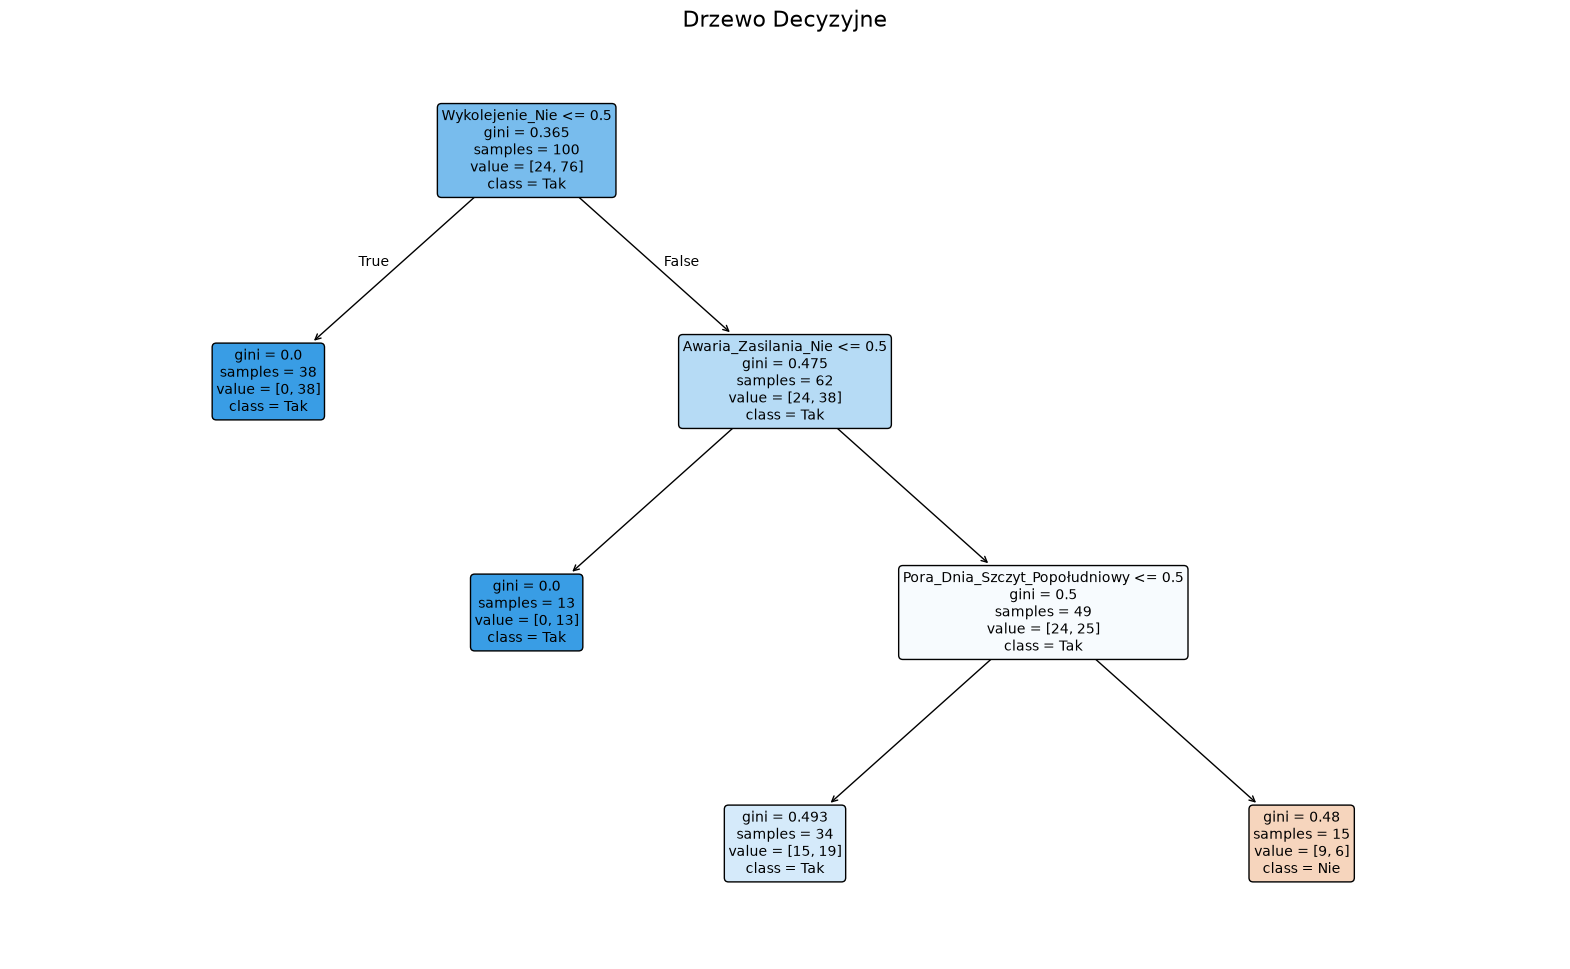

Tekstowa reprezentacja drzewa decyzyjnego (Dostępna)
- [WĘZEŁ] [Start] Korzeń drzewa
  Statystyki: Gini: 0.365, Próbek: 100, Rozkład: [24, 76], Klasa: Tak
    - [LIŚĆ] Jeśli Wykolejenie_Nie <= 0.500
      Statystyki: Gini: 0.000, Próbek: 38, Rozkład: [0, 38], Klasa: Tak
    - [WĘZEŁ] Jeśli Wykolejenie_Nie > 0.500
      Statystyki: Gini: 0.475, Próbek: 62, Rozkład: [24, 38], Klasa: Tak
        - [LIŚĆ] Jeśli Awaria_Zasilania_Nie <= 0.500
          Statystyki: Gini: 0.000, Próbek: 13, Rozkład: [0, 13], Klasa: Tak
        - [WĘZEŁ] Jeśli Awaria_Zasilania_Nie > 0.500
          Statystyki: Gini: 0.500, Próbek: 49, Rozkład: [24, 25], Klasa: Tak
            - [LIŚĆ] Jeśli Pora_Dnia_Szczyt_Popołudniowy <= 0.500
              Statystyki: Gini: 0.493, Próbek: 34, Rozkład: [15, 19], Klasa: Tak
            - [LIŚĆ] Jeśli Pora_Dnia_Szczyt_Popołudniowy > 0.500
              Statystyki: Gini: 0.480, Próbek: 15, Rozkład: [9, 6], Klasa: Nie


In [65]:
# Tworzymy i trenujemy model drzewa decyzyjnego
# Stworzymy proste drzewo o maksymalnej głębokości 3, żeby było czytelne
# criterion='gini' - określamy, że drzewo będzie budowane w oparciu o nieczystość Giniego
# ustawienie argumentu random_state zapewnia, że drzewo będzie wyglądać za każdym razem tak samo 
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=2025)

# Uczymy drzewo na naszych danych
clf.fit(X_encoded, y)

# Wizualizujemy drzewo
plot_tree_wrapper(clf, 
          feature_names=feature_names, 
          class_names=clf.classes_)  # ['Nie', 'Tak']

Powyższe drzewo przedstawia podział danych wraz z ich klasyfikacją na grupy Opóźniony Tak / Nie. Do wyuczenia drzewa użyliśmy algorytmu **CART** (Classification and Regression Trees). Jego celem jest zbudowanie drzewa (grafu), w którym na podstawie wartości atrybutów (cech, np. "Wykolejenie_Nie"), jak najlepiej podzielimy kursy na dwie grupy - te punktualne i te spóźnione. Do oceny jakości podziału wykorzystaliśmy współczynnik *nieczystości Giniego* (Gini Impurity). Za chwilę dowiesz się jak on działa, jednak najpierw rozszyfrujmy drzewo.

**Jak jednak czytać to drzewo?**

Każdy prostokąt to *węzeł* (grupa kursów tramwaju).

1.  **Zaczynamy od góry (korzeń, *ang. root*):** `Wykolejenie_Nie <= 0.5`
      * Warunek `Wykolejenie_Nie <= 0.5` decyduje, w którą gałąź drzewa trafi kurs. 
      * To pytanie o wartość cechy `Wykolejenie_Nie`. Jeśli przyjmuje wartość `True` (czyli 1), to `1 <= 0.5` jest fałszem (False).
      * W lewo (**True**) jest równoznaczne z powiedzeniem `Wykolejenie_Tak` (`Wykolejenie_Nie == 0`). Wtedy wiadomo, że tramwaj będzie opóźniony. W prawo zaś (**False**) oznacza `Wykolejenie_Nie == 1`, co wiąże się z koniecznością sprawdzenia kolejnych warunków.
2. `gini = 0.365` - Tyle wynosi nieczystość na początku ze względu na przewidywaną klasę (24 'Nie' i 76 'Tak').
3. `samples = 100` - W tym węźle są wszystkie kursy.
4. `value = [24, 76]` - [Liczba 'Nie', Liczba 'Tak']
5. `class = Tak` - Klasą dominującą jest 'Tak'.


Wyuczone drzewo pozwala nam wykonać **dedukcję** - na podstawie faktów o nowym kursie przechodzimy przez drzewo do wniosku. Wniosek jest jednak tylko tak pewny jak reguła, o czym mówi wyliczona ufność.

**Reguły (ścieżki w drzewie):**

  - **Ścieżka 1 (W Lewo):**
      - `JEŻELI wykolejenie_nie = False`
      - `gini = 0.0` - Idealnie czysty węzeł
      - `samples = 38`
      - `value = [0, 38]` (0 'Nie', 38 'Tak')
      - `class = Tak`
      - **REGUŁA ze ścieżki 1:** `JEŻELI (Wykolejenie == 'Tak') TO (Opóźniony == 'Tak')`. Wsparcie wyniesie $38/100 = 0,38$, a ufność $38/38 = 1,0$.

  - **Ścieżka 2 (W Prawo, potem w lewo):**
      - `JEŻELI (Wykolejenie == 'Nie')` I `Awaria zasilania = Tak (0 <= 0.5)`
      - `gini = 0.0` - Idealnie czysty węzeł
      - `samples = 13`
      - `value = [0, 13]`
      - `class = Tak`
      - **REGUŁA ze ścieżki 2:** `JEŻELI (wykolejenie == 'nie' I Awaria zasilania = 'Tak') TO (Opóźniony == 'Tak')`. (Wsparcie $0,13$, ufność $1,0$)

  - **Ścieżka 3 (W Prawo, potem w prawo):**

      - `JEŻELI (Wykolejenie == 'Nie')` I `Awaria zasilania == 'Nie' (1 <= 0.5)`
      - `gini = 0.5` - Daleko od ideału
      - `samples = 49`
      - `value = [24, 25]`
      - `class = Tak`
      - Moglibyśmy na tym etapie stworzyć regułę, jednak nie byłaby ona zbyt konstruktywna. W węźle 24 próbki są o wartości Nie i 25 o wartości Tak, czyli reguła opierałaby się na przewadze wynoszącej jedną próbkę (ufność $25/49 \approx 0,51$).

### 🧑‍🎓 Zadanie

Korzystając z powyższego przykładu, opisz dwie pozostałe reguły z wyświetlonego drzewa. Czy reguły z ostatniego poziomu drzewa opisują prawdziwą zależność? Ile kursów je wspiera? Porównaj je z wcześniejszym wnioskiem o wpływie pory dnia.

*Wnioski*
1. Ścieżka (W prawo → w prawo → w lewo):
      • Warunek: JEŻELI (Wykolejenie == 'Nie' I Awaria_Zasilania == 'Nie' I Pora_Dnia_Szczyt_Popołudniowy == 'Nie') TO (Opóźniony == 'Tak')
      • Statystyki: gini = 0.493, samples = 34, value = [15, 19], class = Tak
2. Ścieżka (W prawo → w prawo → w prawo):
      • Warunek: JEŻELI (Wykolejenie == 'Nie' I Awaria_Zasilania == 'Nie' I Pora_Dnia_Szczyt_Popołudniowy == 'Tak') TO (Opóźniony == 'Nie')
      • Statystyki: gini = 0.480, samples = 15, value = [9, 6], class = Nie


regułu z ostatniego poziomu drzewa
mają dalej doś wysoki gini bliski 50%
ufność tych reguł nie jest zbyt wysokoa
19 / 34 ~0.56
9 / 15 = 0.6
i ich wsparcie jest niskie
0.19
i 0.09
wiec nie można uznać ich za prawdziwą zależność


Intuicyjna reguła zakładała, że godziny szczytu powodują opóźnienia (Pora_Dnia = Szczyt => Opóźniony = Tak, ufność 0.75), jednak już w Apriori współczynnik lift ≈ 0.99 pokazał, że szczyt i
  opóźnienia są od siebie niemal niezależne.
 Drzewo decyzyjne potwierdza ten wniosek: gdy wykluczymy wykolejenia i awarie zasilania, sama pora dnia nie daje dobrego podziału (Gini ≈ 0.48–0.49)


### Proces tworzenia drzewa

Algorytm CART na każdym etapie sprawdza jak najlepiej podzielić dane wg dostępnych atrybutów tak, aby jak najbardziej zbliżyć się do zadanego celu, czyli rozdzielenia zadanych klas i umożliwienia przeprowadzenia klasyfikacji (w naszym przypadku, bo może służyć też do regresji). Do oceny jakości podziału wykorzystaliśmy współczynnik nieczystości Giniego, dany wzorem:


$$G = 1 - \sum_{i=1}^{n}p_i^2 $$

gdzie $p_i$ jest prawdopodobieństwem wystąpienia elementu należącego do klasy $i$.

W CART współczynnik ten jest wykorzystywany do wybrania atrybutu w węźle. Celem jest minimalizowanie go, ponieważ ogólnie mówiąc, dla problemu dwuklasowego:

* **Gini Impurity = 0:** Węzeł jest "idealnie czysty" (np. na 5 kursów wszystkie były punktualne).
* **Gini Impurity = 0.5:** Węzeł jest "idealnie nieczysty" w problemie 2-klasowym (najgorszy możliwy; np. 4 kursy punktualne, 4 spóźnione).

Sprawdźmy to na przykładzie:

In [66]:
trams_df.head(5)

,Linia,Pora_Dnia,Opóźniony,Wykolejenie,Awaria_Zasilania,Przez_Arkady_Capitol
0,4,Szczyt_Popołudniowy,Nie,Nie,Nie,Nie
1,10,Szczyt_Popołudniowy,Tak,Tak,Tak,Tak
2,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak
3,17,Szczyt_Popołudniowy,Tak,Nie,Nie,Nie
4,17,Szczyt_Popołudniowy,Tak,Tak,Nie,Tak


Dla powyższego przykładu, gdzie mamy 2 klasy i ich rozkład 1:4 (1 kurs nieopóźniony, 4 opóźnione):

$G = 1 - ((\frac{1}{5})^2 + (\frac{4}{5})^2) = \frac{8}{25} = 0.32 $

Tak liczone wartości są wpisane w węzłach naszego drzewa. Jak jednak algorytm dokonuje wyboru, której cechy użyć do podziału na danym etapie?

CART sprawdza po kolei dostępne cechy (atrybuty) i używa ich do podzielenia przewidywanych klas. Dla każdego atrybutu oblicza ważone Gini Impurity po podziale, tzn. ile Tak i Nie znajdzie się w węźle do którego prowadzi odpowiedź twierdząca na warunek (True), a ile w węźle do którego prowadzi odpowiedź przecząca.

Weźmy powyższy przykład 5 przejazdów.

Dla podziału względem cechy `Wykolejenie`:

* Odpowiedź Tak zawsze (3 kursy) wiązała się z opóźnieniem ($G = 0$).
* Odpowiedź Nie w 50% przypadków (po 1 kursie) wiązała się z opóźnieniem ($G = 1 - (\frac{1}{2})^2 - (\frac{1}{2})^2 = \frac{1}{2}$).
* Współczynnik ważony liczbą przypadków wyniesie: $G_{ważone} = \frac{3}{5}\times0 + \frac{2}{5}\times\frac{1}{2} = \frac{1}{5}$

Na tym etapie dla podziału względem cechy `Awaria_Zasilania`:
* Odpowiedź Tak zawsze (1 kurs) wiązała się z opóźnieniem ($G = 0$).
* Odpowiedź Nie (4 kursy) w 75% przypadków (3 kursy) wiązała się z opóźnieniem ($G = 1 - (\frac{3}{4})^2 - (\frac{1}{4})^2 = \frac{6}{16}$).
* Współczynnik ważony liczbą przypadków wyniesie: $G_{ważone} = \frac{1}{5}\times0 + \frac{4}{5}\times\frac{6}{16} = \frac{6}{20}$

W tym przypadku, spośród tych dwóch cech, `Wykolejenie` zostałoby wybrane jako warunek podziału ze względu na niższą wartość $G_{ważone}$ (czyli lepsze rozdzielenie klas).

<!-- Algorytm CART sprawdza po kolei dla wszystkich atrybutów ich szuka takiego pytania (np. `Pora_Dnia=Szczyt?`), które po podziale da nam dwa *jak najczystsze* węzły potomne. -->

### Predykcja z wykorzystaniem drzewa

Wytrenowane drzewo możemy wykorzystać do przewidywania wyników na podstawie zadanych atrybutów. Wejściem jest zbiór cech w postaci tablicy, zatem kolejność atrybutów musi się dokładnie pokrywać z danymi uczącymi. Do uczenia modelu wykorzystaliśmy `X_encoded`, którego nazwy atrybutów są zapisane w `feature_names`.

In [67]:
X_encoded

array([[1., 0., 0., ..., 0., 1., 0.],
       [0., 0., 1., ..., 1., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 1., 1., 0.]], shape=(100, 13))

In [68]:
feature_names

array(['Linia_4', 'Linia_5', 'Linia_10', 'Linia_17',
       'Pora_Dnia_Poza_Szczytem', 'Pora_Dnia_Szczyt_Popołudniowy',
       'Pora_Dnia_Szczyt_Poranny', 'Wykolejenie_Nie', 'Wykolejenie_Tak',
       'Awaria_Zasilania_Nie', 'Awaria_Zasilania_Tak',
       'Przez_Arkady_Capitol_Nie', 'Przez_Arkady_Capitol_Tak'],
      dtype=object)

Stwórzmy teraz przykład, którego nie ma w bazie danych: **Tramwaj linii 4, kurs w szczycie porannym, przejazd przez Arkady Capitol, bez wykolejenia, bez awarii zasilania**. Nasz klasyfikator spróbuje odpowiedzieć czy taki tramwaj będzie opóźniony.

In [69]:
# Kolejność jak w feature_names:
# Linia_4, Linia_5, Linia_10, Linia_17, Poza_Szczytem, Szczyt_Popołudniowy, Szczyt_Poranny,
# Wykolejenie_Nie, Wykolejenie_Tak, Awaria_Zasilania_Nie, Awaria_Zasilania_Tak,
# Przez_Arkady_Capitol_Nie, Przez_Arkady_Capitol_Tak
new_sample = np.array([True, False, False, False, False, False, True,
                        True, False, True, False, False, True]).reshape(1, -1)

clf.predict(new_sample)

array(['Tak'], dtype=object)

Nasz model odpowiedział, że tramwaj będzie opóźniony. Sprawdźmy to na schemacie drzewa. Kurs nie był wykolejony (`Wykolejenie_Nie = 1`, warunek `<= 0.5` fałszywy, idziemy w prawo) i nie miał awarii (`Awaria_Zasilania_Nie = 1`, znów w prawo). Dochodzimy do pytania `Pora_Dnia_Szczyt_Popołudniowy <= 0.5`. Warunek jest prawdziwy, ponieważ kurs jest w szczycie porannym - `Pora_Dnia_Szczyt_Popołudniowy = 0`. Idziemy w lewo. W tym liściu, spośród 34 kursów poza szczytem popołudniowym, bez wykolejenia i bez awarii, 19 jest opóźnionych, a 15 punktualnych. Drzewo przewiduje więc opóźnienie. 

*Zauważ, że drzewo nie pyta o przejazd przez Arkady Capitol: w danych uczących ta cecha niczego nie dodawała do informacji o wykolejeniu.*

### 🧑‍🎓 Zadanie

Wykorzystaj kod poniżej, aby załadować i przetworzyć dane. Następnie:

* Wyucz drzewo decyzyjne przewidujące końcową ocenę ucznia (G3). Wyświetl wyuczone drzewo.
* Zapisz 1 regułę z drzewa według własnego uznania i policz jej support, confidence i lift.
* Sprawdź jak zmienia się drzewo, gdy usuniesz z danych oceny okresowe G1 i G2. 

Podpowiedź:

```python
  # Oceny zostały zakodowane jako kolumny 0/1, stąd nazwy:
  X_no_marks = X_encoded.drop(columns=["G1_Pass", "G1_Excellent", "G2_Pass", "G2_Excellent"])
  feature_names_no_marks = X_no_marks.columns.tolist()
```
    
Zapisz wnioski z wykonanego zadania.

In [70]:
edu_df = load_uci()

X_encoded, y, feature_names, class_names = prepare_exp_uci(edu_df)

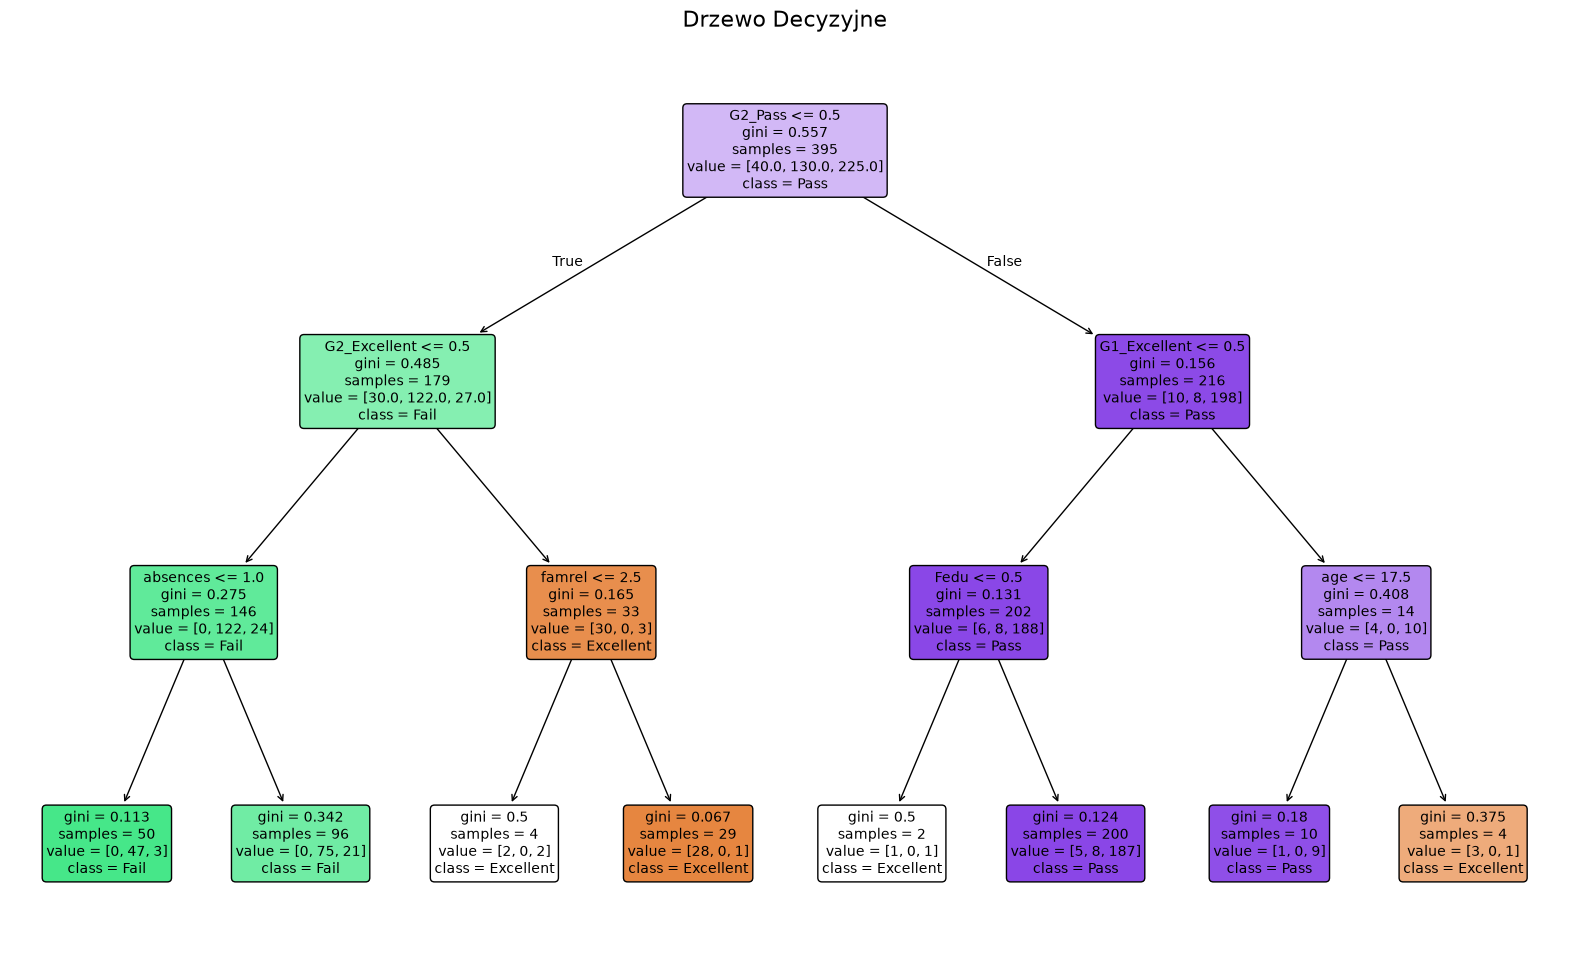

Tekstowa reprezentacja drzewa decyzyjnego (Dostępna)
- [WĘZEŁ] [Start] Korzeń drzewa
  Statystyki: Gini: 0.557, Próbek: 395, Rozkład: [40, 130, 225], Klasa: Pass
    - [WĘZEŁ] Jeśli G2_Pass <= 0.500
      Statystyki: Gini: 0.485, Próbek: 179, Rozkład: [30, 122, 27], Klasa: Fail
        - [WĘZEŁ] Jeśli G2_Excellent <= 0.500
          Statystyki: Gini: 0.275, Próbek: 146, Rozkład: [0, 122, 24], Klasa: Fail
            - [LIŚĆ] Jeśli absences <= 1.000
              Statystyki: Gini: 0.113, Próbek: 50, Rozkład: [0, 47, 3], Klasa: Fail
            - [LIŚĆ] Jeśli absences > 1.000
              Statystyki: Gini: 0.342, Próbek: 96, Rozkład: [0, 75, 21], Klasa: Fail
        - [WĘZEŁ] Jeśli G2_Excellent > 0.500
          Statystyki: Gini: 0.165, Próbek: 33, Rozkład: [30, 0, 3], Klasa: Excellent
            - [LIŚĆ] Jeśli famrel <= 2.500
              Statystyki: Gini: 0.500, Próbek: 4, Rozkład: [2, 0, 2], Klasa: Excellent
            - [LIŚĆ] Jeśli famrel > 2.500
              Statystyki: Gini: 

In [71]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=2025)

# Uczymy drzewo na naszych danych
clf.fit(X_encoded, y)

# Wizualizujemy drzewo
plot_tree_wrapper(clf, 
          feature_names=feature_names, 
          class_names=clf.classes_,
          )

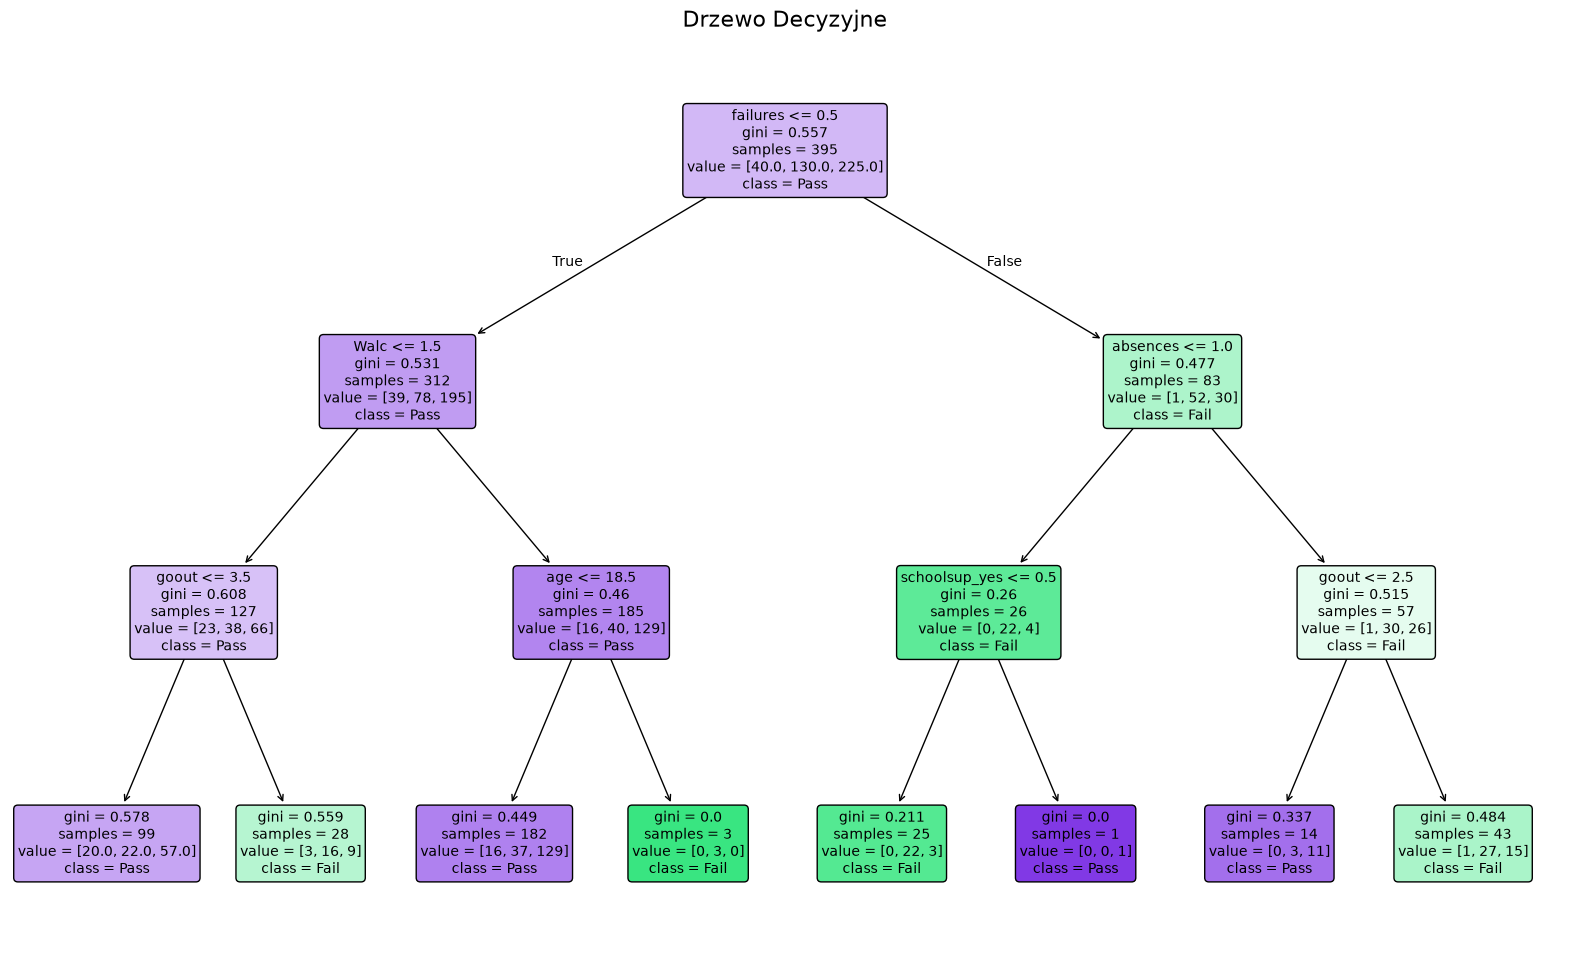

Tekstowa reprezentacja drzewa decyzyjnego (Dostępna)
- [WĘZEŁ] [Start] Korzeń drzewa
  Statystyki: Gini: 0.557, Próbek: 395, Rozkład: [40, 130, 225], Klasa: Pass
    - [WĘZEŁ] Jeśli failures <= 0.500
      Statystyki: Gini: 0.531, Próbek: 312, Rozkład: [39, 78, 195], Klasa: Pass
        - [WĘZEŁ] Jeśli Walc <= 1.500
          Statystyki: Gini: 0.608, Próbek: 127, Rozkład: [23, 38, 66], Klasa: Pass
            - [LIŚĆ] Jeśli goout <= 3.500
              Statystyki: Gini: 0.578, Próbek: 99, Rozkład: [20, 22, 57], Klasa: Pass
            - [LIŚĆ] Jeśli goout > 3.500
              Statystyki: Gini: 0.559, Próbek: 28, Rozkład: [3, 16, 9], Klasa: Fail
        - [WĘZEŁ] Jeśli Walc > 1.500
          Statystyki: Gini: 0.460, Próbek: 185, Rozkład: [16, 40, 129], Klasa: Pass
            - [LIŚĆ] Jeśli age <= 18.500
              Statystyki: Gini: 0.449, Próbek: 182, Rozkład: [16, 37, 129], Klasa: Pass
            - [LIŚĆ] Jeśli age > 18.500
              Statystyki: Gini: 0.000, Próbek: 3, Rozkła

In [82]:
X_no_marks = X_encoded.drop(columns=["G1_Pass", "G1_Excellent", "G2_Pass", "G2_Excellent"])
feature_names_no_marks = X_no_marks.columns.tolist()

clf_no_marks = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=2025)
clf_no_marks.fit(X_no_marks, y)

plot_tree_wrapper(
    clf_no_marks,
    feature_names=feature_names_no_marks,
    class_names=clf_no_marks.classes_
)

In [81]:
len(edu_df)

395

In [80]:
len(edu_df[edu_df.G3 == 'Excellent'])

40

*Wnioski*

Jeżeli G2_Pass == 0 i G2_Excellent == 1 i famrel > 2.5 to G3_Excellent == 1
gini = 0.067
samples = 29
values  = [28,0,1]
class = Excellent

supp = 28 / 395 ~0.07
conf = 28/29 ~0.96
lift = conf / (40/395) = 9.5
Bardzo silna zaleznosc

Drzewo bez G1 i G2
ma znacznie większe gini w węzłach co sprawia ze powstałe reguły gorzej bedą się przekładać na rzeczywsitość



Literatura i źródła:

1. Cortez, P. (2008). Student Performance [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T. (dostęp 24.02.2026)
2. T. Morzy, M. Morzy, A. Leśniewska, *Eksploracja danych*, Ważniak (MIM UW), https://wazniak.mimuw.edu.pl/index.php?title=Eksploracja_danych (dostęp 24.02.2026)
3. J. Stefanowski, *Association rules*, Politechnika Poznańska, https://www.cs.put.poznan.pl/jstefanowski/sed/DM10-association-rules.pdf (dostęp 24.02.2026)
4. Dokumentacja Scikit-learn - drzewa decyzyjne, https://scikit-learn.org/stable/modules/tree.html (dostęp 24.02.2026)
5. J. Han, J. Pei, H. Tong, *Data Mining: Concepts and Techniques*, 4th ed., Morgan Kaufmann 2022
6. M. Moczurad, W. Moczurad, *Paradygmaty programowania*, Studia Informatyczne (Ważniak), wykład 13 „Programowanie w logice w Prologu I” i wykład 14 „Programowanie w logice w Prologu II”, https://wazniak.mimuw.edu.pl/index.php?title=Paradygmaty_programowania/Wyk%C5%82ad_14:_Programowanie_w_logice_w_Prologu_II (dostęp 24.02.2026)
7. P. Fulmański, *Programowanie w logice. Prolog*, skrypt, Uniwersytet Łódzki, 2009, rozdz. 1–3, https://fulmanski.pl/zajecia/prolog/wyklad.pdf (dostęp 24.02.2026)
8. Russell, Stuart; Norvig, Peter. Artificial Intelligence: A Modern Approach, 4th ed., Pearson, 2020 
9. Włodzisław Duch, Sztuczna Inteligencja Reprezentacja wiedzy IV. Systemy produkcyjne, ramy, skrypty, mapy argumentów, https://www.is.umk.pl/~duch/Wyklady/AI25/AI06-2-rep-inne.pdf (dostęp 24.02.2026)

*Przy tworzeniu materiałów wykorzystano metody generatywne sztucznej inteligencji do generowania kodu według wytycznych autora i poprawy jakości prezentowanego tekstu. Generowane treści podlegały walidacji i zmianom przez autora materiału.*

Autor materiału: dr inż. Bartosz Perz

![Stopka - Edu PWr](./img/footer.png) EDU PWR - edukacja na Politechnice Wrocławskiej w odpowiedzi na potrzeby nowoczesnej gospodarki i rynku pracy.